In [ ]:
# Deep Learning Practical: MNIST classification using a Feedforward Neural Network
# Works offline if either the Keras MNIST cache or a local MNIST image folder is available.

import os
import glob
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from PIL import Image

print("TensorFlow Version:", tf.__version__)

# 1. Load MNIST data.
# Keras cache location is usually ~/.keras/datasets/mnist.npz.
keras_mnist_path = os.path.expanduser("~/.keras/datasets/mnist.npz")

if os.path.isfile(keras_mnist_path):
    # This exact call works offline when MNIST is already cached locally.
    from tensorflow.keras.datasets import mnist
    (x_train, y_train), (x_test, y_test) = mnist.load_data()
else:
    # Offline fallback: read a local image dataset organized as:
    # mnist-jpg/train/0 ... mnist-jpg/train/9
    # mnist-jpg/test/0  ... mnist-jpg/test/9
    # The folder may be named mnist_dataset/mnist-jpg instead.
    possible_roots = [
        "mnist-jpg",
        "mnist_dataset/mnist-jpg",
        "mnist_dataset",
        "./dataset/mnist-jpg",
        "./dataset"
    ]
    dataset_root = None
    for root in possible_roots:
        if os.path.isdir(os.path.join(root, "train")) and os.path.isdir(os.path.join(root, "test")):
            dataset_root = root
            break

    if dataset_root is None:
        raise FileNotFoundError(
            "MNIST data was not found offline. Put mnist.npz in ~/.keras/datasets/ "
            "or extract your local image dataset so that it has train/0...9 and test/0...9 folders."
        )

    def load_split(split_dir):
        images, labels = [], []
        for label in range(10):
            class_dir = os.path.join(split_dir, str(label))
            if not os.path.isdir(class_dir):
                raise FileNotFoundError(
                    f"Missing class folder: {class_dir}. Expected folders named 0 through 9."
                )
            files = []
            for ext in ("*.png", "*.jpg", "*.jpeg", "*.bmp", "*.webp"):
                files.extend(glob.glob(os.path.join(class_dir, ext)))
                files.extend(glob.glob(os.path.join(class_dir, ext.upper())))
            for file in files:
                with Image.open(file) as img:
                    img = img.convert("L").resize((28, 28))
                    images.append(np.asarray(img, dtype=np.uint8))
                    labels.append(label)
        if not images:
            raise ValueError(f"No image files found under {split_dir}")
        return np.asarray(images), np.asarray(labels, dtype=np.uint8)

    x_train, y_train = load_split(os.path.join(dataset_root, "train"))
    x_test, y_test = load_split(os.path.join(dataset_root, "test"))

print("Training data shape:", x_train.shape)
print("Testing data shape:", x_test.shape)

# 2. Normalize pixel values from 0-255 to 0-1.
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# 3. Flatten each 28 x 28 image into 784 input features.
x_train = x_train.reshape(-1, 784)
x_test = x_test.reshape(-1, 784)

# 4. Define the Feedforward Neural Network.
model = keras.Sequential([
    keras.Input(shape=(784,)),
    layers.Dense(128, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax")
])

model.summary()

# 5. Compile the model using SGD.
model.compile(
    optimizer=keras.optimizers.SGD(learning_rate=0.01),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# 6. Train the model.
history = model.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

# 7. Evaluate the model on test data.
test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=1)
print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

# 8. Plot training and validation loss.
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.tight_layout()
plt.show()

# 9. Plot training and validation accuracy.
plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.tight_layout()
plt.show()


TensorFlow Version: 2.21.0


FileNotFoundError: MNIST data was not found offline. Put mnist.npz in ~/.keras/datasets/ or extract your local image dataset so that it has train/0...9 and test/0...9 folders.

In [3]:
import os

print("Current folder:", os.getcwd())
print("Downloads contents:", os.listdir(os.path.expanduser("~/Downloads")))

Current folder: /home/ubuntu
Downloads contents: ['Titanic-Dataset.xls', 'B3_titanic_classification.ipynb', 'iron-man-red-glow--24338.png', 'Assignment_2_Linear_Regression(1).ipynb', 'archive(4)', 'archive(1) (3)', 'Untitled2.ipynb', 'archive (3)', 'C1_Clustering_Techniques(2).ipynb', 'diabetes(1).xls', 'archive(1) (4)', 'cifar-10-img (1).zip', '.~lock.Titanic-Dataset.xls#', 'archive(4).zip', 'diabetes.ipynb', 'Lab3_TEITA71.ipynb', 'SIH2026-IDEA-Presentation-Format.pptx', 'archive(11).zip', 'creditcardfraud-csv (1).zip', 'archive(7).zip', 'DL 2.pdf', 'house price', 'TE - Computer Engineering - 2024 Pattern.pdf', 'mnist_dataset', 'archive (5)', 'Assignment_2_3_MNIST (1).ipynb', 'archive(9).zip', 'BFS&DFS(2).ipynb', 'Mall_Customers.csv', 'Copy of B3_titanic_classification.ipynb', 'archive(3)', 'DL 2-1.pdf', 'Assignment_2_Linear_Regression.ipynb', 'diabetes(1).ipynb', 'DL_1st (1)(1).ipynb', '.ipynb_checkpoints', 'housing (4).csv', 'archive(8) (3)', 'archive(1) (5)', 'BFS.ipynb', 'C1_Clust

In [4]:
import os

path = os.path.expanduser("~/Downloads/mnist_dataset")

print("Dataset folder exists:", os.path.exists(path))

if os.path.exists(path):
    for root, dirs, files in os.walk(path):
        print(root)
        print("Subfolders:", dirs[:10])
        print("Files:", files[:5])

        if root.count(os.sep) - path.count(os.sep) >= 3:
            dirs[:] = []

Dataset folder exists: True
/home/ubuntu/Downloads/mnist_dataset
Subfolders: ['mnist-jpg']
Files: []
/home/ubuntu/Downloads/mnist_dataset/mnist-jpg
Subfolders: ['train', 'test']
Files: []
/home/ubuntu/Downloads/mnist_dataset/mnist-jpg/train
Subfolders: ['9', '4', '1', '7', '2', '5', '6', '8', '3', '0']
Files: []
/home/ubuntu/Downloads/mnist_dataset/mnist-jpg/train/9
Subfolders: []
Files: ['34052.jpg', '22108.jpg', '48457.jpg', '48344.jpg', '44762.jpg']
/home/ubuntu/Downloads/mnist_dataset/mnist-jpg/train/4
Subfolders: []
Files: ['24032.jpg', '27424.jpg', '30745.jpg', '37311.jpg', '17744.jpg']
/home/ubuntu/Downloads/mnist_dataset/mnist-jpg/train/1
Subfolders: []
Files: ['14327.jpg', '48112.jpg', '36731.jpg', '42581.jpg', '2563.jpg']
/home/ubuntu/Downloads/mnist_dataset/mnist-jpg/train/7
Subfolders: []
Files: ['36615.jpg', '12428.jpg', '39845.jpg', '22921.jpg', '54494.jpg']
/home/ubuntu/Downloads/mnist_dataset/mnist-jpg/train/2
Subfolders: []
Files: ['3965.jpg', '43994.jpg', '20695.jpg',

TensorFlow Version: 2.21.0
Training data shape: (60000, 28, 28)
Testing data shape: (10000, 28, 28)
Training labels shape: (60000,)
Testing labels shape: (10000,)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8319 - loss: 0.6223 - val_accuracy: 0.0065 - val_loss: 9.1371
Epoch 2/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 2s 961us/step - accuracy: 0.9246 - loss: 0.2610 - val_accuracy: 0.0070 - val_loss: 10.1762
Epoch 3/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 2s 960us/step - accuracy: 0.9380 - loss: 0.2134 - val_accuracy: 0.0068 - val_loss: 10.3446
Epoch 4/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 2s 924us/step - accuracy: 0.9479 - loss: 0.1826 - val_accuracy: 0.0075 - val_loss: 10.3955
Epoch 5/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 2s 921us/step - accuracy: 0.9540 - loss: 0.1598 - val_accuracy: 0.0072 - val_loss: 11.0870
Epoch 6/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 2s 953us/step - accuracy: 0.9587 - loss: 0.1421 - val_accuracy: 0.0073 - val_loss: 11.1587
Epoch 7/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 2s 945us/step - accuracy: 0.9635 - loss: 0.1278 - val_accuracy: 0.0075 - val_loss: 10.9260
Epoch 8/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 2s 926us/step - accuracy: 0.96

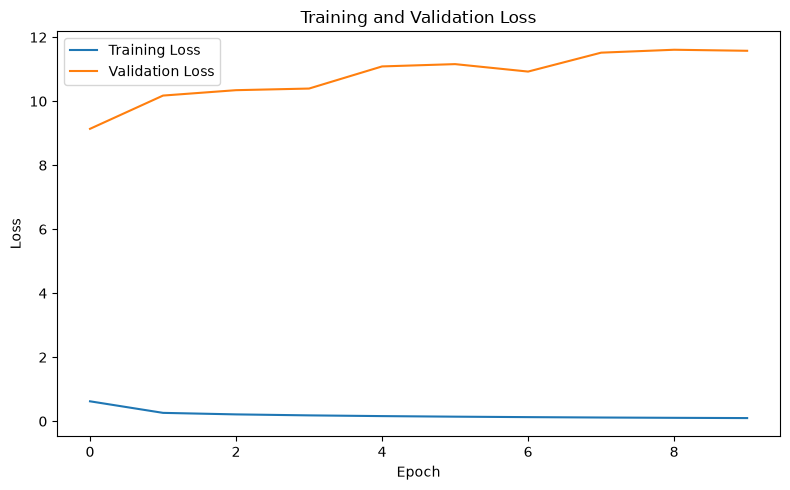

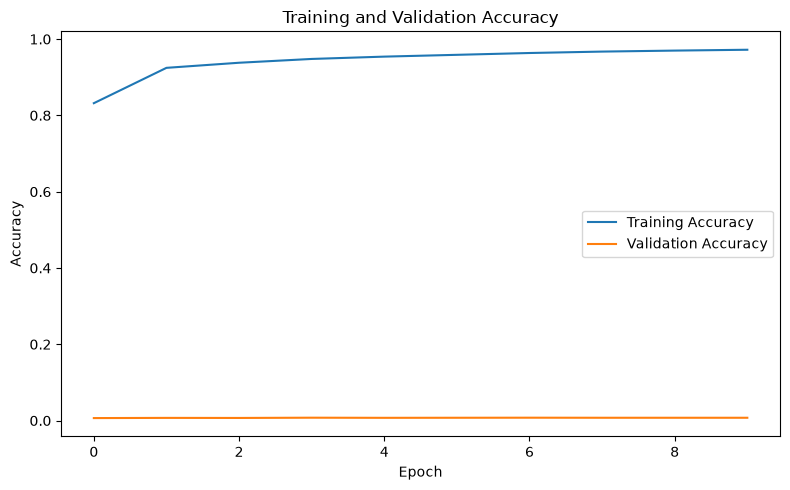

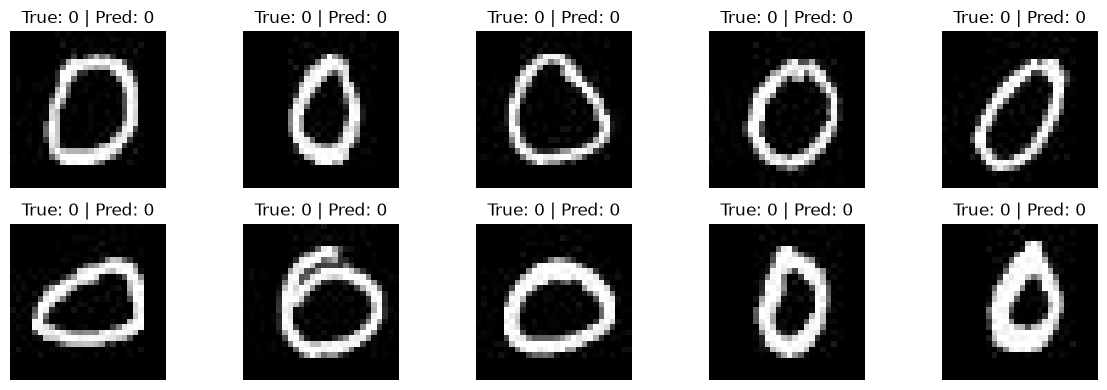

In [7]:
# MNIST Feedforward Neural Network - Offline Jupyter Notebook
# Uses the local image dataset in ~/Downloads/mnist_dataset/mnist-jpg
# No internet connection or dataset download is required.

import os
import glob
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow Version:", tf.__version__)

# 1. Load MNIST from local image folders
DATASET_ROOT = os.path.expanduser("~/Downloads/mnist_dataset/mnist-jpg")

def load_split(split_name):
    split_dir = os.path.join(DATASET_ROOT, split_name)
    if not os.path.isdir(split_dir):
        raise FileNotFoundError(f"Folder not found: {split_dir}")

    images, labels = [], []
    for digit in range(10):
        class_dir = os.path.join(split_dir, str(digit))
        if not os.path.isdir(class_dir):
            raise FileNotFoundError(f"Missing digit folder: {class_dir}")

        files = []
        for pattern in ("*.jpg", "*.jpeg", "*.png", "*.bmp", "*.JPG", "*.JPEG", "*.PNG"):
            files.extend(glob.glob(os.path.join(class_dir, pattern)))
        files = sorted(set(files))

        for file_path in files:
            with Image.open(file_path) as img:
                img = img.convert("L").resize((28, 28))
                arr = np.asarray(img, dtype=np.uint8)
                # Standard MNIST images have white digits on black background.
                # Keep the loaded image as-is; normalize below.
                images.append(arr)
                labels.append(digit)

    if not images:
        raise ValueError(f"No image files found under {split_dir}/0 ... {split_dir}/9")

    return np.asarray(images, dtype=np.uint8), np.asarray(labels, dtype=np.uint8)

x_train, y_train = load_split("train")
x_test, y_test = load_split("test")

print("Training data shape:", x_train.shape)
print("Testing data shape:", x_test.shape)
print("Training labels shape:", y_train.shape)
print("Testing labels shape:", y_test.shape)

# 2. Normalize pixel values
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# 3. Flatten each 28x28 image to 784 features
x_train = x_train.reshape(-1, 784)
x_test = x_test.reshape(-1, 784)

# 4. Define the feedforward neural network
model = keras.Sequential([
    keras.Input(shape=(784,)),
    layers.Dense(128, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax")
])

model.summary()

# 5. Compile model
model.compile(
    optimizer=keras.optimizers.SGD(learning_rate=0.01),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# 6. Train model
history = model.fit(
    x_train, y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

# 7. Evaluate model
test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=1)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f} ({test_accuracy * 100:.2f}%)")

# 8. Plot training and validation loss
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.tight_layout()
plt.show()

# 9. Plot training and validation accuracy
plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.tight_layout()
plt.show()

# 10. Display a few test predictions
predictions = model.predict(x_test[:10], verbose=0)
predicted_labels = np.argmax(predictions, axis=1)

plt.figure(figsize=(12, 4))
for i in range(min(10, len(x_test))):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i].reshape(28, 28), cmap="gray")
    plt.title(f"True: {y_test[i]} | Pred: {predicted_labels[i]}")
    plt.axis("off")
plt.tight_layout()
plt.show()